# Explore benchmark results

This notebook shows a few ways to explore saved experiments with **Yanex**, work
with tables in **pandas**, and customise plots with **matplotlib**. Use the examples
as a starting point for analysing your own experiments.

If you haven't done so yet, first run the 3 yanex experiments in order, from the `experiments` directory:

```sh
cd experiments
```

#### 1. Prepare database

Execute the database preparation experiment first. It will set up the database, download and insert the data. 

```sh
yanex run prepare_db.py -c configs/prepare.yaml -n "1-prepare"
```

Note the experiment ID returned by this command. 

#### 2. Generate workload

Next, generate the workload using the experiment ID from the prepare step above. 
This tells yanex that the experiment depends on the results of another. 

```sh
yanex run workload.py -c configs/workload.yaml -D prepare=<prepare-id> -n "2-workload"
```

Again, note the experiment ID returned by this command.

#### 3. Run benchmark

Finally, run the benchmark using the experiment ID from the workload step. This ensures that the benchmark uses the generated workload.

Here, we use the sweep notation on the `index_set` parameter, running it for all 3 index sets: `baseline`, `single`, and `compound`.
The experiments are executed sequentially. Make sure to use the same name with `-n "3-benchmark"` as this name will be used
to filter on the experiments in the notebook cells below. 

```sh
yanex run benchmark.py -c configs/benchmark.yaml \
  -D workload=<workload-id> -p 'index_set=baseline,single,compound' -n "3-benchmark"
```

#### 4. Optionally shut down the database

After completing the experiments, you may want to shut down the database to free up resources. 
The notebook cells below don't need the database anymore and instead get their data from the saved yanex experiments.

Use `stop` to pause the database while retaining its data. The MongoDB deployment name is `bondi-demo`.
Resume it later with `bondi start bondi-demo`. To permanently delete the deployment and its data, use `bondi remove bondi-demo`.

```bash
bondi list
bondi stop bondi-demo
```

## Setup

The [yanex Results API](https://github.com/rueckstiess/yanex/blob/main/docs/results-api.md) allows you to retrieve experiments and their saved results. [pandas](https://pandas.pydata.org/) provides DataFrames for tabular analysis; [matplotlib](https://matplotlib.org/) draws the charts. 

`rcParams` sets a few plotting defaults for the notebook.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import yanex.results as yr
from IPython.display import display

plt.rcParams.update({"figure.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})

## 1. Find and compare experiments

[`yr.compare()`](https://github.com/rueckstiess/yanex/blob/main/docs/results-api.md#yanexresultscompareparamsnone-metricsnone-only_differentfalse-filters) searches the local Yanex store and returns a DataFrame, similar to
the `yanex compare` CLI command. Here we filter by project and experiment name;
the `*` matches names beginning with `3-benchmark`, which we've used for the benchmark experiments with the `-n` (short for `--name`) option.

`meta`, `params`, and `metrics` select which columns to include. The `*_ms` pattern
selects the timing metrics with that suffix. The columns returned by `yr.compare()` include prefixes for `meta:`, `params:`, and `metrics:` to disambiguate potential naming clashes. We remove them for better readability.

See the [Yanex Results API](https://github.com/rueckstiess/yanex/blob/main/docs/results-api.md)
for more ways to find and inspect experiments.

In [3]:
runs = yr.compare(
    project="bondi-demo-project",
    name="3-benchmark*",
    meta=["id", "name", "status"],  # only include experiment ID, name and status from metadata
    params=["index_set"],  # only include the index_set parameter
    metrics=["*_ms"],  # include all metrics ending in "_ms"
)

# remove the prefixes before : to simplify column names
runs.columns = [col.split(":", 1)[-1] for col in runs.columns]

display(runs)

,name,status,index_set,median_workload_ms,workloads_ms
experiment_id,,,,,
06b61ca2,3-benchmark-compound,completed,compound,950.3687,"989.2084174789488, 936.2528324127197, 950.3687..."
dcf8abf8,3-benchmark-single,completed,single,813.9838,"810.8074222691357, 813.98383108899, 829.388999..."
71b8b97a,3-benchmark-baseline,completed,baseline,6060.1143,"6025.124377105385, 6060.114332940429, 6136.304..."


## 2. Calculate speedups and plot workload times

pandas lets us select the baseline row with `.loc` and calculate a new column:
**speedup = baseline time / run time**. A value of `5.2` means the workload ran
5.2 times as fast as the baseline. This example uses the first baseline match,
so the search above should contain exactly one comparison.

The bar chart shows the logged median workload time across repetitions; lower
bars are better. `DataFrame.plot.bar()` creates the plot, and matplotlib's
`bar_label()` adds the speedup annotations. Try changing the figure size, colours,
or labels for your own reports.

In [4]:
# Add speedup compared to baseline to the runs DataFrame
baseline = runs.loc[runs["index_set"] == "baseline", "median_workload_ms"].values[0]

runs["speedup_vs_baseline"] = baseline / runs["median_workload_ms"]
display(runs.round(2))

,name,status,index_set,median_workload_ms,workloads_ms,speedup_vs_baseline
experiment_id,,,,,,
06b61ca2,3-benchmark-compound,completed,compound,950.37,"989.2084174789488, 936.2528324127197, 950.3687...",6.38
dcf8abf8,3-benchmark-single,completed,single,813.98,"810.8074222691357, 813.98383108899, 829.388999...",7.45
71b8b97a,3-benchmark-baseline,completed,baseline,6060.11,"6025.124377105385, 6060.114332940429, 6136.304...",1.00


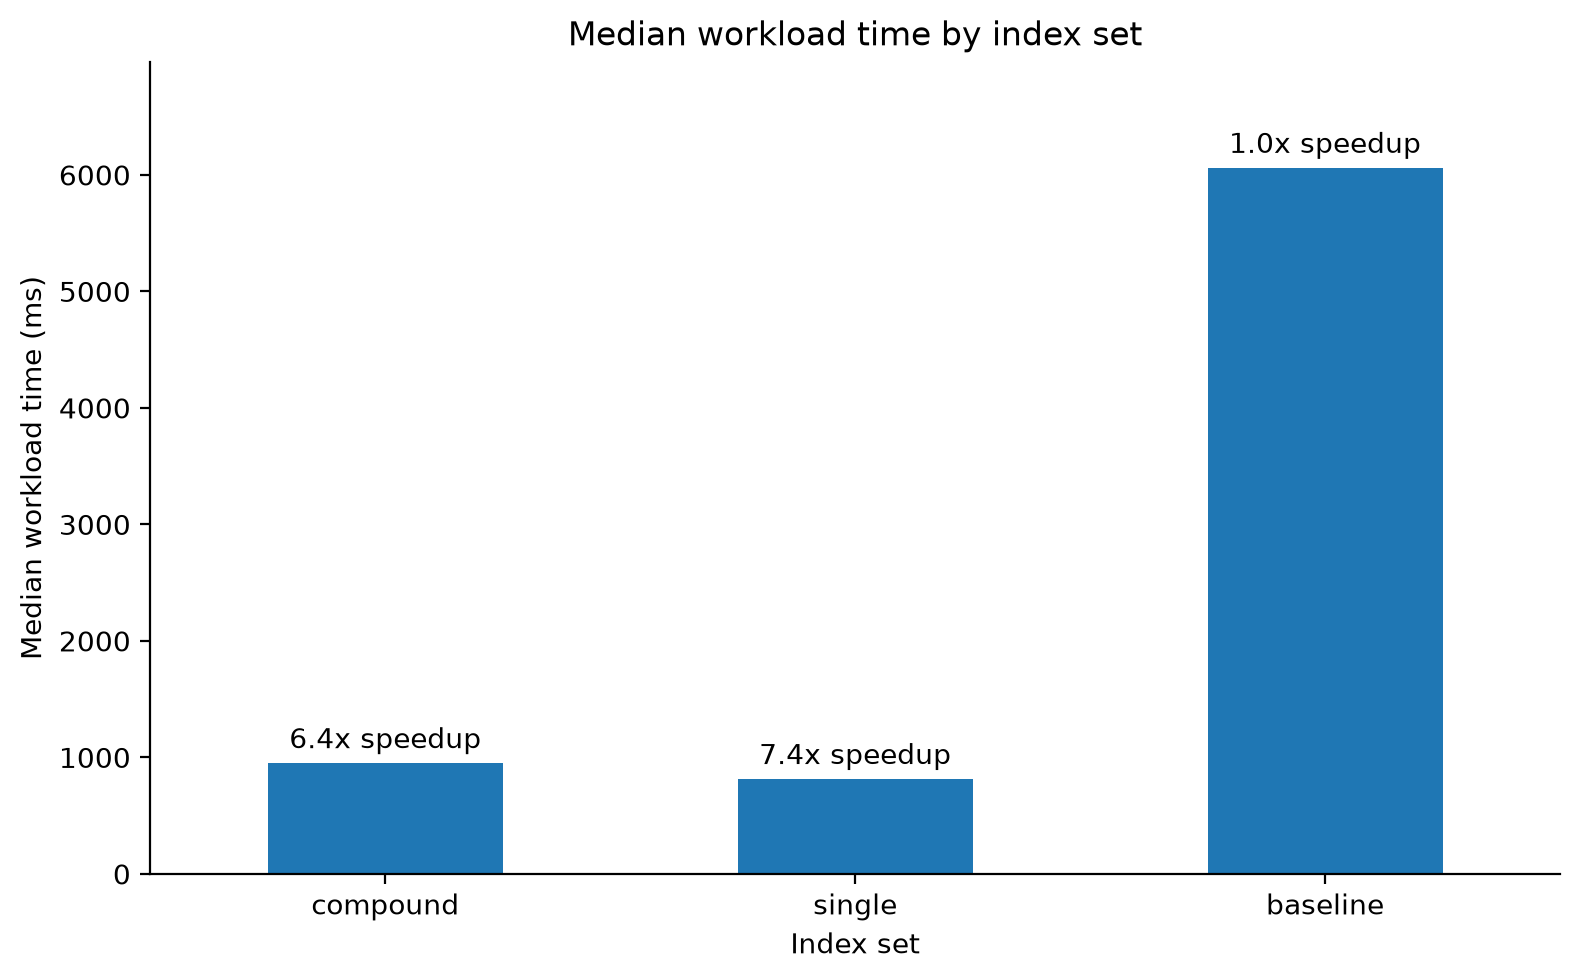

In [5]:
ax = runs.plot.bar(
    x="index_set",
    y="median_workload_ms",
    figsize=(8, 5),
    legend=False,
    rot=0,
)
ax.set(
    title="Median workload time by index set",
    xlabel="Index set",
    ylabel="Median workload time (ms)",
)
ax.bar_label(
    ax.containers[0],
    labels=[f"{speedup:.1f}x speedup" for speedup in runs["speedup_vs_baseline"]],
    padding=3,
)
ax.margins(y=0.15)  # Leave room for the labels above the bars.
plt.tight_layout()
plt.show()

## 3. Load and summarise individual query measurements

`yr.get_experiments()` returns experiment objects rather than a comparison table.
Each object gives access to its parameters through `get_param()` and saved files
through `load_artifact()`. Use the same search filters as in the comparison above.

Each `query_results.jsonl` row represents one query in one measured repetition.
We add the index set and experiment ID with `assign()`, then use `pd.concat()` to
combine the runs. `query_id` identifies a query's position in the saved workload;
`pattern_id` groups queries with the same shape.

The `groupby(...).agg(...)` example calculates count, median, mean, minimum and
maximum query times across repetitions. With the default configuration, each
query has three observations per index set. Try selecting one pattern or sorting
the summary by `mean_ms` to find expensive queries.

In [6]:
# Get experiments for the 3 matching benchmark runs
benchmarks = yr.get_experiments(project="bondi-demo-project", name="3-benchmark*")

# Load individual query results and concatenate them all in a DataFrame
queries = pd.concat(
    [
        pd.DataFrame(exp.load_artifact("query_results.jsonl")).assign(
            index_set=exp.get_param("index_set"),
            experiment_id=exp.id,
        )
        for exp in benchmarks
    ],
    ignore_index=True,
)

# make sure all queries finished successfully
assert queries["status"].eq("success").all(), "Inspect failed queries before comparing timings."

# Display the first few query results for inspection
display(queries.head(5))

# Group by (pattern, query, index_set) and calculate statistics for elapsed time
stats = queries.groupby(["pattern_id", "query_id", "index_set"])["elapsed_ms"].agg(
    count="count",
    median_ms="median",
    mean_ms="mean",
    min_ms="min",
    max_ms="max",
)
display(stats.round(2))

,repetition,query_id,pattern_id,elapsed_ms,row_count,status,error,index_set,experiment_id
0,0,0,3,1.385833,41,success,None,compound,06b61ca2
1,0,1,3,2.362958,10,success,None,compound,06b61ca2
2,0,2,2,5.652791,256,success,None,compound,06b61ca2
3,0,3,1,1.295584,56,success,None,compound,06b61ca2
4,0,4,0,2.021042,0,success,None,compound,06b61ca2


count  median_ms  mean_ms  min_ms  max_ms
pattern_id query_id index_set                                           
0          4        baseline       3      47.19    47.98   46.74   50.01
                    compound       3       1.14     1.43    1.13    2.02
                    single         3       1.09     1.05    0.86    1.20
           9        baseline       3      47.36    48.19   47.19   50.01
                    compound       3       1.26     1.32    1.10    1.61
...                              ...        ...      ...     ...     ...
4          88       compound       3       9.63     9.70    9.45   10.03
                    single         3       9.91    10.01    9.83   10.30
           98       baseline       3      73.31    73.83   72.09   76.10
                    compound       3       3.63     3.53    3.27    3.69
                    single         3       3.49     3.50    3.45    3.57

[300 rows x 5 columns]

## 4. Compare patterns with a grouped bar chart

`pivot_table()` reshapes the measurements into one row per pattern and one column
per benchmark run. Each value is the **mean query execution time**, averaging all
instances and measured repetitions within that pattern. pandas then draws the
columns as grouped bars, labelled by index set.

This complements the overall workload comparison: an index set may improve the
total time while helping some patterns more than others. These are client-observed
query times, including result fetching, with warm-ups and index creation excluded.

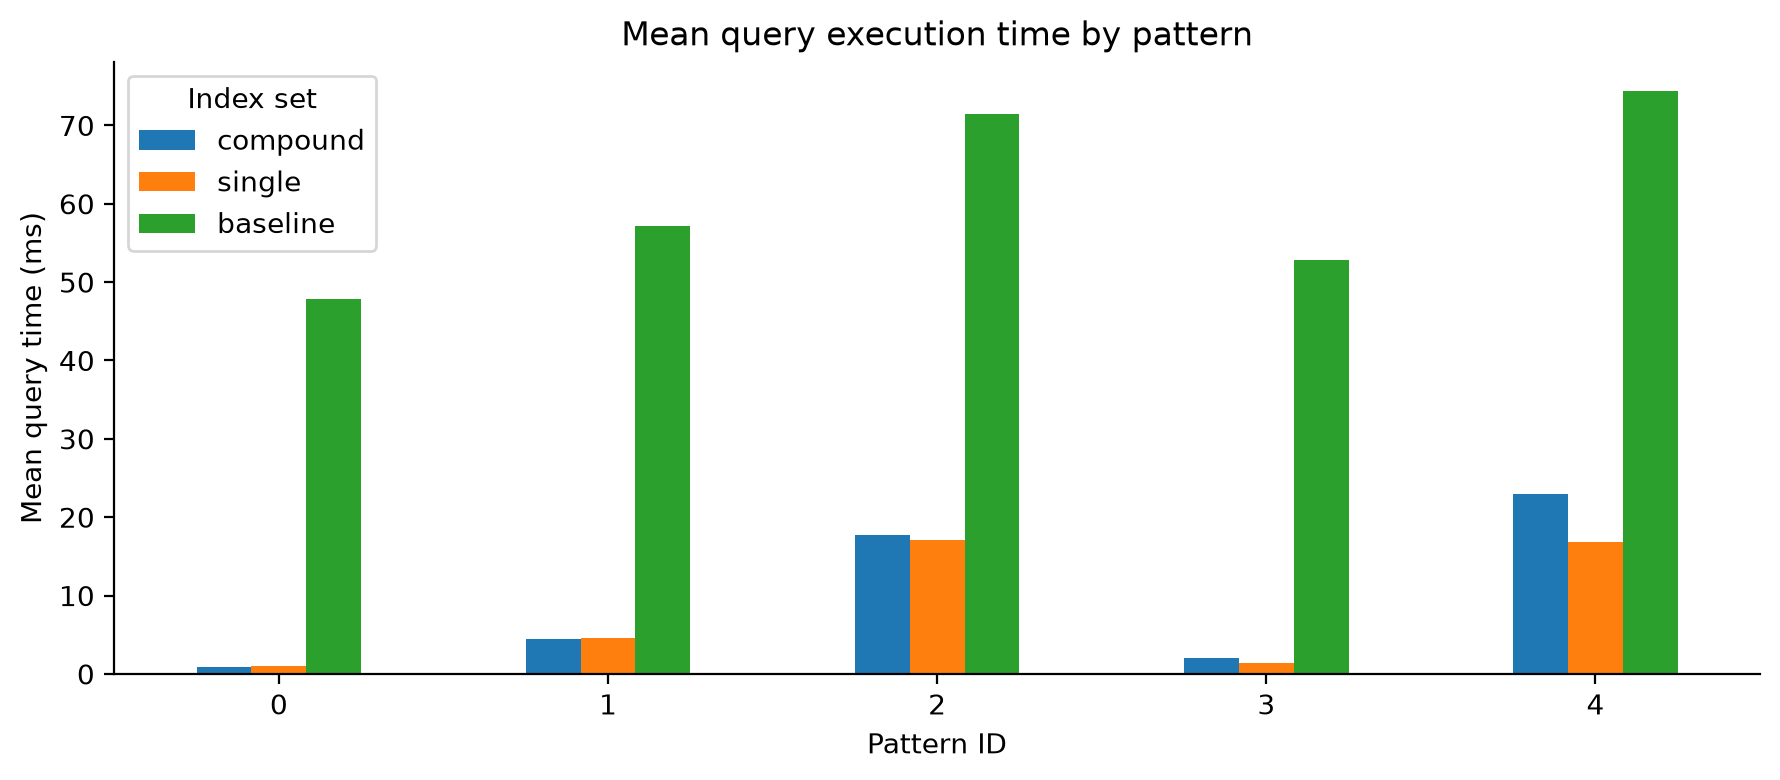

In [7]:
pattern_ids = sorted(queries["pattern_id"].unique())
run_ids = [exp.id for exp in benchmarks]
labels = [exp.get_param("index_set") for exp in benchmarks]
colors = plt.get_cmap("tab10").colors[: len(run_ids)]

# Each group contains one bar per benchmark run, averaging instances and repetitions.
pattern_times = queries.pivot_table(
    index="pattern_id",
    columns="experiment_id",
    values="elapsed_ms",
    aggfunc="mean",
).reindex(index=pattern_ids, columns=run_ids)
pattern_times.columns = labels
ax = pattern_times.plot.bar(figsize=(9, 4), rot=0, color=colors)
ax.set(
    title="Mean query execution time by pattern", xlabel="Pattern ID", ylabel="Mean query time (ms)"
)
ax.legend(title="Index set")
plt.tight_layout()
plt.show()

In [ ]:
from bondi.mongodb import MongoQueryPattern

# load the patterns from the workload experiment that the benchmarks depend on
workload_exp = benchmarks[0].get_dependency("workload")
patterns = [MongoQueryPattern.from_dict(p) for p in workload_exp.load_artifact("patterns.jsonl")]

for i, p in enumerate(patterns):
    print(f"Pattern {i}: {p}")

Pattern 0: bondi_demo.electric_vehicles: City $eq <str> AND Make $in <10 × str> AND Model Year $lte <int> | sort={'City': 1} | limit=14
Pattern 1: bondi_demo.electric_vehicles: City $in <4 × str> AND State $nin <2 × str> | sort={'Make': -1, 'City': -1}
Pattern 2: bondi_demo.electric_vehicles: City $lte <str> AND Color $eq <str>
Pattern 3: bondi_demo.electric_vehicles: Color $eq <str> AND Make $in <10 × str> AND Model Year $lte <int> | limit=41
Pattern 4: bondi_demo.electric_vehicles: City $nin <6 × str> AND Make $in <8 × str> AND Model Year $gt <int> | sort={'City': 1, 'State': 1} | limit=6


## Explore further

- Which index set is fastest overall? Does it win for every pattern?
- Filter `queries` to one pattern or query to inspect its individual repetitions.
- Change `aggfunc="mean"` to `"median"` and compare the pattern chart.
- Export a table with `stats.to_csv("query_stats.csv")` or a plot with
  `ax.figure.savefig("pattern_times.png", bbox_inches="tight")`.

Three repetitions give a useful first look, but repeat the experiments and vary
the run order before drawing strong conclusions about performance.

More examples: [pandas tutorials](https://pandas.pydata.org/docs/getting_started/intro_tutorials/),
[matplotlib tutorials](https://matplotlib.org/stable/tutorials/index.html), and
[Yanex Results API](https://github.com/rueckstiess/yanex/blob/main/docs/results-api.md).